In [6]:
import requests
import pandas as pd

BASE_URL = "https://clinicaltrials.gov/api/v2/studies"


def fetch_trials(condition, cell_type_keyword, limit=100):
    """Fetch trials from ClinicalTrials.gov API v2."""
    params = {
        "pageSize": min(limit, 100),
        "fields": "NCTId,BriefTitle,OverallStatus,Phase,StudyType,StartDate,Organization,InterventionName,LocationCountry"
    }
    if condition:
        params["query.cond"] = condition
    if cell_type_keyword:
        params["query.term"] = cell_type_keyword

    response = requests.get(BASE_URL, params=params, headers={"Accept": "application/json"}, timeout=45)
    response.raise_for_status()
    return response.json().get("studies", [])


def parse_trials(studies):
    """Parse API response into a clean df."""
    records = []
    for study in studies:
        ps = study.get("protocolSection", {})
        ident = ps.get("identificationModule", {})
        status_mod = ps.get("statusModule", {})
        design = ps.get("designModule", {})
        arms = ps.get("armsInterventionsModule", {})
        contacts = ps.get("contactsLocationsModule", {})

        start_date = status_mod.get("startDate", {})
        start_year = None
        if isinstance(start_date, dict):
            start_year = start_date.get("year")
        elif isinstance(start_date, str):
            try:
                start_year = int(start_date[:4])
            except Exception:
                pass

        phases = design.get("phases", [])
        locations = contacts.get("locations", [])
        countries = list({loc.get("country", "") for loc in locations if loc.get("country")})
        interventions = arms.get("interventions", [])

        records.append({
            "NCT ID": ident.get("nctId", "N/A"),
            "Title": ident.get("briefTitle", "Untitled"),
            "Status": status_mod.get("overallStatus", "UNKNOWN"),
            "Phase": phases[0] if phases else "NA",
            "Study Type": design.get("studyType", "N/A"),
            "Interventions": ", ".join(i.get("name", "") for i in interventions) if interventions else "N/A",
            "Country": countries[0] if countries else "Not Specified",
            "Start Year": start_year,
        })
    return pd.DataFrame(records)
print (parse_trials(fetch_trials("Parkinsons", "stem cell")))

        NCT ID                                              Title  \
0  NCT03104725  Does N-Acetylcysteine Decrease Spontaneous Oxi...   
1  NCT06944522  A Study to Investigate the Efficacy and Safety...   
2  NCT05573542           Early Signs of Parkinsons Disease in IBS   
3  NCT02795052               Neurologic Stem Cell Treatment Study   

                    Status   Phase      Study Type  \
0               TERMINATED  PHASE1  INTERVENTIONAL   
1               RECRUITING  PHASE3  INTERVENTIONAL   
2  ENROLLING_BY_INVITATION      NA   OBSERVATIONAL   
3               RECRUITING      NA  INTERVENTIONAL   

                                    Interventions               Country  \
0  N-Acetylcysteine, Lumbar Puncture, Fluoroscopy         United States   
1                     bemdaneprocel, Sham surgery                Canada   
2                                             N/A                Sweden   
3                 Intravenous and Intranasal BMSC  United Arab Emirates   

  Start

Output()

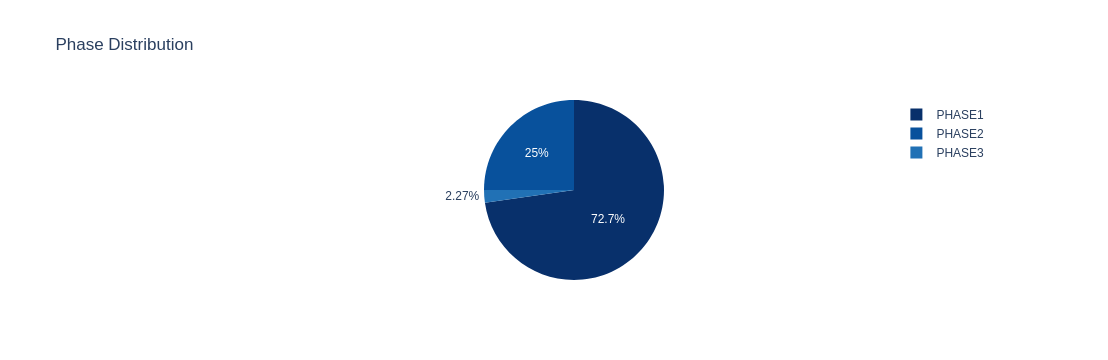

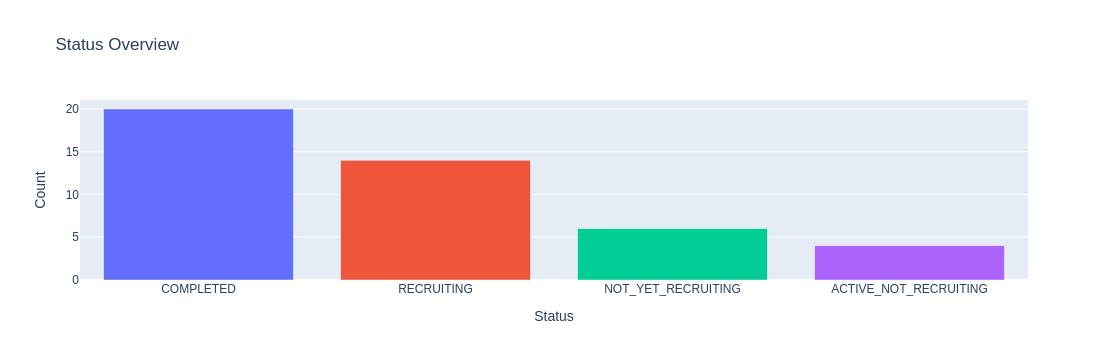

,NCT ID,Title,Status,Phase,Study Type,Country,Start Year
2,NCT07554872,Study of Neural Stem Cell-Derived Exosomes in ...,NOT_YET_RECRUITING,PHASE1,INTERVENTIONAL,China,None
5,NCT01758510,Safety Study of HLA-haplo Matched Allogenic Bo...,COMPLETED,PHASE1,INTERVENTIONAL,South Korea,None
7,NCT05152394,Safety of Cultured Allogeneic Adult Umbilical ...,RECRUITING,PHASE1,INTERVENTIONAL,Antigua and Barbuda,None
8,NCT01051882,Autologous Cultured Mesenchymal Bone Marrow St...,COMPLETED,PHASE1,INTERVENTIONAL,Israel,None
14,NCT04684602,Mesenchymal Stem Cells for the Treatment of Va...,RECRUITING,PHASE1,INTERVENTIONAL,United States,None
16,NCT02540655,Efficacy and Safety Study of Stemchymal® in Po...,COMPLETED,PHASE2,INTERVENTIONAL,Taiwan,None
19,NCT07638813,MSC-Exosome Therapy for Frontotemporal Dementia,NOT_YET_RECRUITING,PHASE1,INTERVENTIONAL,Not Specified,None
24,NCT01825551,The Effect of GCSF in the Treatment of ALS Pat...,COMPLETED,PHASE2,INTERVENTIONAL,Iran,None
29,NCT03252535,Dose-response Evaluation of the Cellavita HD P...,COMPLETED,PHASE2,INTERVENTIONAL,Brazil,None
31,NCT05947578,The Safety and Tolerability of CLZ-2002 in Pat...,COMPLETED,PHASE1,INTERVENTIONAL,South Korea,None



Saved as neuroregen_trials_20260728.csv — download it from the Colab Files panel on the left.


In [10]:
import plotly.express as px
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display, clear_output
from datetime import datetime

condition_options = [
    "Neurodegenerative Diseases", "Parkinson Disease", "Alzheimer Disease",
    "Amyotrophic Lateral Sclerosis", "Spinal Cord Injuries",
    "Traumatic Brain Injury", "Multiple Sclerosis", "Stroke",
]
status_options = ["RECRUITING", "ACTIVE_NOT_RECRUITING", "COMPLETED",
                   "NOT_YET_RECRUITING", "SUSPENDED", "WITHDRAWN", "TERMINATED"]
phase_options = ["EARLY_PHASE1", "PHASE1", "PHASE1|PHASE2", "PHASE2",
                  "PHASE2|PHASE3", "PHASE3", "PHASE4", "NA"]

condition_dd = widgets.Dropdown(options=condition_options, description="Condition:", style={"description_width": "initial"})
cell_type_txt = widgets.Text(value="stem cell", description="Cell type:", style={"description_width": "initial"})
status_sel = widgets.SelectMultiple(options=status_options,
                                     value=("RECRUITING", "ACTIVE_NOT_RECRUITING", "COMPLETED", "NOT_YET_RECRUITING"),
                                     description="Status:", style={"description_width": "initial"}, rows=4)
phase_sel = widgets.SelectMultiple(options=phase_options,
                                    value=("PHASE1", "PHASE1|PHASE2", "PHASE2", "PHASE2|PHASE3", "PHASE3"),
                                    description="Phase:", style={"description_width": "initial"}, rows=4)
max_results_slider = widgets.IntSlider(value=100, min=10, max=500, step=10, description="Max results:", style={"description_width": "initial"})
run_button = widgets.Button(description="Update dashboard", button_style="primary", icon="refresh")
output = widgets.Output()


def render_dashboard(_=None):
    with output:
        clear_output(wait=True)
        try:
            raw = fetch_trials(condition_dd.value, cell_type_txt.value, max_results_slider.value)
            df = parse_trials(raw)
            if status_sel.value:
                df = df[df["Status"].isin(status_sel.value)]
            if phase_sel.value:
                df = df[df["Phase"].isin(phase_sel.value)]
        except Exception as e:
            print(f"Live API error ({e})")

        # Metrics
        n_recruiting = int((df["Status"] == "RECRUITING").sum())
        n_completed = int((df["Status"] == "COMPLETED").sum())
        n_countries = df["Country"].nunique()
        print(f"Total trials: {len(df)}   |   Recruiting: {n_recruiting}   |   "
              f"Completed: {n_completed}   |   Countries: {n_countries}")

        if df.empty:
            print("No trials match the current filters.")
            return

        # Phase pie chart
        phase_counts = df["Phase"].value_counts().reset_index()
        phase_counts.columns = ["Phase", "Count"]
        fig1 = px.pie(phase_counts, values="Count", names="Phase", title="Phase Distribution",
                      color_discrete_sequence=px.colors.sequential.Blues_r)
        fig1.show()

        # Status bar chart
        status_counts = df["Status"].value_counts().reset_index()
        status_counts.columns = ["Status", "Count"]
        fig2 = px.bar(status_counts, x="Status", y="Count", color="Status", title="Status Overview")
        fig2.update_layout(showlegend=False)
        fig2.show()

        # Timeline
        if "Start Year" in df.columns and df["Start Year"].notna().any():
            timeline = df[df["Start Year"].notna()].groupby("Start Year").size().reset_index(name="Count")
            fig3 = px.line(timeline, x="Start Year", y="Count", markers=True, title="Trial Timeline")
            fig3.show()

        # Table
        display(df[["NCT ID", "Title", "Status", "Phase", "Study Type", "Country", "Start Year"]])

        # Save CSV for download in Colab (Files panel on the left)
        fname = f"neuroregen_trials_{datetime.now().strftime('%Y%m%d')}.csv"
        df.to_csv(fname, index=False)
        print(f"\nSaved as {fname} — download it from the Colab Files panel on the left.")


run_button.on_click(render_dashboard)

controls = widgets.VBox([
    widgets.HBox([condition_dd, cell_type_txt]),
    widgets.HBox([status_sel, phase_sel]),
    run_button,
])
display(controls, output)
render_dashboard()  # initial render with defaults